# Modelagem de Tópicos com a TF-IDF

A TD-IDF, como visto na aula anterior, representa os textos de forma matricial e leva em conta a importância de cada token em conta. A partir da TF-IDF, podemos realizar uma modelagem de tópicos, ou seja, podemos classicar nossos documentos os agrupando, no nosso caso, faremos isso para resumos de artigos. Vamos começar o procedimento obtendo nossa TD-IDF.

### Lendo os abstracts

In [1]:
import pandas as pd
import os
import re

Ler todos arquivos da Web of Science:

In [2]:
dfs = []

for arquivo in os.listdir('../Data/'):
    if arquivo.endswith('.xls'):
        caminho_arquivo = os.path.join('../Data/', arquivo)
        
        df_temporario = pd.read_excel(caminho_arquivo)
        
        dfs.append(df_temporario)

dados_total = pd.concat(dfs, ignore_index=True)

# Pré processamento

In [3]:
import spacy
nlp = spacy.load('en_core_web_sm')

doc_objs = list()
for abst in dados_total['Abstract']:
    abst = str(abst)
    doc_objs.append(nlp(abst))

In [4]:
from tqdm import tqdm

chemical_pattern = r'\b(?:[A-Z][a-z]?(?:\d+(?:\.\d*)?|\.\d+)?){2}[A-Z][a-z]?(?:\d+(?:\.\d*)?|\.\d+)?(?:\(?3\)?)\b'

####### Add most common words as stopwords
nlp.Defaults.stop_words |= {"perovskite", "material", "property", "structure", "application", "study"}

def preprocess_text(text):
    processed_tokens = []
    for token in nlp(text):
        if re.match(chemical_pattern, token.text):
            processed_tokens.append(token.text)
            #print(token.text)
        else:
            processed_tokens.append(token.text.lower())
    return ' '.join(processed_tokens)

preprocessed_abstracts = []
for abstract in tqdm(dados_total['Abstract']):
    if isinstance(abstract, str):
        preprocessed_abstracts.append(preprocess_text(abstract))
    else:
        preprocessed_abstracts.append("")

dados_total['Abstract'] = preprocessed_abstracts

dados_total['Abstract'] = dados_total['Abstract'].apply(lambda x: ' '.join([token.text for token in nlp(x) if not token.is_stop]))

# for i,abst in enumerate(list(dados_total['Abstract'])):
#     print(i,abst)

100%|██████████| 14220/14220 [14:15<00:00, 16.61it/s]


___

Transformar os abstracts em uma lista.

In [5]:
abstracts = list()
for abst in dados_total['Abstract']:
    abstracts.append(str(abst))

Transformar os títulos em uma lista.

In [6]:
titles = list()
for tls in dados_total['Article Title']:
    titles.append(str(tls))

Importar bibliotecas necessárias.

In [7]:
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline

Obter a TF-IDF.

In [8]:
tfidf = TfidfVectorizer()
csr_mat = tfidf.fit_transform(abstracts)
words = tfidf.get_feature_names_out()
print(csr_mat)

  (0, 17751)	0.04950587460293075
  (0, 13615)	0.06815096792643716
  (0, 2891)	0.06340475175657158
  (0, 2316)	0.0959875997296395
  (0, 38935)	0.055840825523254506
  (0, 24697)	0.07490343772667618
  (0, 1224)	0.065318245871548
  (0, 19601)	0.10434208438911874
  (0, 4208)	0.0768785176869288
  (0, 18995)	0.06696768375229462
  (0, 21757)	0.10715437983551866
  (0, 8991)	0.13343939731705337
  (0, 31445)	0.07209560221867602
  (0, 18990)	0.07437539046289393
  (0, 9848)	0.07246712620372657
  (0, 39525)	0.09656277798357771
  (0, 42938)	0.05627931767242325
  (0, 47768)	0.14035701100032602
  (0, 15915)	0.13988145849738073
  (0, 20758)	0.04371186807684966
  (0, 42202)	0.06001221427157648
  (0, 49414)	0.07238379847880179
  (0, 7233)	0.04771911652561704
  (0, 21545)	0.08209126969487729
  (0, 32686)	0.10138664909119172
  :	:
  (14219, 11319)	0.04659534419437407
  (14219, 12228)	0.16236550633660504
  (14219, 39103)	0.05142645631134127
  (14219, 16865)	0.03649168235577526
  (14219, 35234)	0.033584469907

In [9]:
print(tfidf.vocabulary_)

{'mn': 30102, 'doped': 17740, 'bfo': 9598, 'thin': 45542, 'films': 20767, 'glass': 22150, 'substrates': 43547, 'simple': 41428, 'spin': 42288, 'coating': 12947, 'method': 29359, 'structural': 43284, 'optical': 33290, 'properties': 37427, 'examined': 19700, 'results': 39600, 'obtained': 32713, 'ray': 38414, 'diffraction': 16904, 'pattern': 34243, 'confirmed': 13676, 'rhombohedral': 39800, 'distorted': 17490, 'stress': 43227, 'relaxation': 39132, 'bi': 9647, 'fe': 20432, 'bonds': 10320, 'detected': 16517, 'shifting': 41153, 'stretching': 43239, 'bending': 9438, 'vibrations': 48035, 'pristine': 37171, 'observed': 32686, 'ftir': 21545, 'analysis': 7233, 'xps': 49414, 'spectra': 42202, 'film': 20758, 'declared': 15915, 'valence': 47768, 'states': 42938, 'respective': 39525, 'binding': 9848, 'energies': 18990, 'narrow': 31445, 'band': 8991, 'gap': 21757, 'energy': 18995, '65': 4208, 'ev': 19601, '17': 1224, 'indicated': 24697, 'reduction': 38935, '2p': 2316, '3d': 2891, 'conduction': 13615, 

In [10]:
df_tf_idf = pd.DataFrame(csr_mat.toarray(), columns = words)
df_tf_idf.T

,0,1,2,3,4,5,6,7,8,9,...,14210,14211,14212,14213,14214,14215,14216,14217,14218,14219
00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zwl,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zx,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zz,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zzpaired,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Função para exibir os tokens mais importantes de um documento.

In [11]:
def TF_IDF_func_presrntation(Num):
    DF = df_tf_idf.T[Num].nlargest(10)
    print( 'Doc number ' , Num+1)
    print( 30*'-')
    return DF

In [12]:
print(TF_IDF_func_presrntation(3000))

Doc number  3001
------------------------------
cr3           0.463571
crcl6         0.355470
nir           0.325408
cs2nasccl6    0.315900
broadband     0.188538
emission      0.159664
octahedron    0.143287
localized     0.137496
rare          0.114377
earth         0.110801
Name: 3000, dtype: float64


### Calculando a SVD

A SVD, do inglês Single Value Decomposition, é uma operação matricial semelhante a encontrar autovalores e autovetores, porém para matrizes não quadradas. O que faremos então, é calcular a SVD da TF-IDF. Abaixo temos uma imagem descrevendo o processo.

Notem que a TF-IDF é uma matriz com n linhas, sendo cada linha um documento, e m colunas, sendo cada coluna um token do vocabulário. Ao realizarmos a SVD, teremos três matrizes, uma com *n* linhas (documentos) e *r* colunas (tópicos), outra com *r* linhas e colunas e por fim uma com *r* linhas e *m* colunas (tokens do vocabulário).

<img src="SVD.png" width=500 />

Portanto, a matriz documentos X tópicos nos fornecerá o quanto cada documento se encaixa em cada tópico, já a matriz token X tópicos, nos informa o quanto cada token está relacionado a cada tópico. Esta análise não informa o que é cada tópico, isso deve ser classificado pelo usuário.

Outro detalhe, é que truncamos a SVD para o número de tópicos que desejamos, abaixo vamos relizar o processo para 10 tópicos. Ao final, a matriz documento-tópico é exibida.

In [13]:
svd = TruncatedSVD(n_components=10)
lsa = svd.fit_transform(csr_mat)

topic_encoded_df = pd.DataFrame(lsa, columns = ["topic_1", "topic_2", "topic_3", "topic_4", "topic_5", "topic_6", "topic_7", "topic_8", "topic_9", "topic_10"])
topic_encoded_df["titles"] = titles
display(topic_encoded_df[["titles", "topic_1", "topic_2", "topic_3", "topic_4", "topic_5", "topic_6", "topic_7", "topic_8", "topic_9", "topic_10"]])

,titles,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9,topic_10
0,Bandgap tuning of Mn-doped BiFeO3 thin films f...,0.130673,-0.126728,-0.047180,-0.065769,-0.046558,0.000754,-0.081480,-0.000073,-0.119135,0.001583
1,Rashba Band Splitting and Bulk Photovoltaic Ef...,0.167779,-0.049361,0.073198,-0.052290,0.096632,0.061028,-0.071754,0.025826,-0.042855,0.004711
2,Switching of Intermetallic Charge Transfer and...,0.103348,-0.114281,-0.083710,0.006771,-0.010929,0.026581,-0.082777,-0.014764,-0.009663,0.019932
3,Probing proton diffusion as a guide to environ...,0.151380,0.002369,0.009928,0.015010,0.025208,0.006241,0.061776,-0.039454,-0.066648,-0.006190
4,Optical detection of nitroaromatic compounds u...,0.083896,-0.087674,0.030918,-0.018557,-0.059532,-0.030309,0.006311,0.034470,-0.013648,-0.045967
...,...,...,...,...,...,...,...,...,...,...,...
14215,In situ growth of CsPbBr3 quantum dots in meso...,0.168689,-0.007180,0.038671,0.236920,-0.080553,-0.086315,-0.133065,-0.017744,-0.075734,-0.116374
14216,Iron-Doped CaTiO3 and Pd/YSZ Dual Bed Catalyti...,0.092387,-0.073622,-0.092022,0.101283,0.060595,0.006379,-0.009649,-0.007887,-0.032973,0.025501
14217,Visible-light photooxidation of ciprofloxacin ...,0.101448,-0.050320,0.010480,0.031735,0.015680,-0.046313,-0.017185,0.001120,-0.025542,-0.030306
14218,"Structural, magnetic and ferroelectric propert...",0.131059,-0.134741,-0.111219,-0.077251,-0.115636,0.052592,0.036162,0.019081,0.083755,0.012275


Vamos exibir a matriz token-tópico:

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

encoding_matrix = pd.DataFrame(svd.components_,
                               index=["topic_1", "topic_2", "topic_3", "topic_4", "topic_5", "topic_6", "topic_7", "topic_8", "topic_9", "topic_10"],
                               columns=words).T
encoding_matrix

,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9,topic_10
00,0.005574,-0.004812,-0.007963,-0.006511,-0.008493,0.003166,-0.001646,-0.000307,0.000196,0.004402
000,0.005983,0.001148,0.001917,0.004021,-0.000986,0.002879,0.007042,0.004254,0.003909,-0.003206
0000,0.000036,-0.000102,-0.000070,-0.000116,-0.000143,0.000064,-0.000080,0.000009,0.000186,0.000016
00000000,0.000371,0.000179,0.000355,0.001323,-0.000532,-0.000491,0.000225,-0.001006,-0.000356,0.000345
00003,0.000025,-0.000063,-0.000026,-0.000100,-0.000008,-0.000009,-0.000093,-0.000019,0.000002,-0.000030
...,...,...,...,...,...,...,...,...,...,...
zwl,0.000076,-0.000127,0.000408,0.000420,-0.000171,-0.000374,-0.000397,-0.000574,-0.000381,0.000476
zx,0.000022,-0.000102,-0.000081,-0.000100,-0.000102,0.000134,-0.000106,-0.000059,0.000033,0.000090
zz,0.000031,-0.000077,0.000020,-0.000104,0.000002,0.000235,0.000014,0.000042,0.000105,0.000001
zzpaired,0.000031,-0.000077,0.000020,-0.000104,0.000002,0.000235,0.000014,0.000042,0.000105,0.000001


Vamos ordenar tópico a tópico agora.

In [15]:
list_of_topics = ["topic_1", "topic_2", "topic_3", "topic_4", "topic_5", "topic_6", "topic_7", "topic_8", "topic_9", "topic_10"]

for topic in list_of_topics:
    encoding_matrix[topic] = np.abs(encoding_matrix[topic])

display(encoding_matrix.sort_values("topic_4", ascending=False))

,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9,topic_10
oxygen,0.058465,0.096434,0.208181,2.006059e-01,0.126369,0.014591,0.043532,0.014261,6.774122e-02,0.030064
cspbbr3,0.060217,0.048499,0.167725,1.837687e-01,0.168620,0.111911,0.020507,0.060673,8.625392e-02,0.019771
surface,0.087839,0.012051,0.031954,1.607269e-01,0.007151,0.058172,0.074557,0.040675,1.341529e-01,0.027173
ncs,0.042120,0.061317,0.174998,1.468215e-01,0.117984,0.161907,0.113992,0.145515,5.945227e-02,0.152341
activity,0.029897,0.053203,0.098600,1.347464e-01,0.089653,0.012578,0.023215,0.007433,5.313356e-02,0.005110
...,...,...,...,...,...,...,...,...,...,...
attractedgreat,0.000029,0.000024,0.000052,2.805408e-08,0.000027,0.000217,0.000134,0.000078,1.813158e-04,0.000117
zrh2,0.000079,0.000091,0.000019,2.550734e-08,0.000008,0.000149,0.000435,0.000201,1.790915e-07,0.000172
hobaco2o6,0.000023,0.000069,0.000107,1.082003e-08,0.000009,0.000028,0.000021,0.000031,3.136989e-05,0.000105
dsffi,0.000023,0.000069,0.000107,1.082003e-08,0.000009,0.000028,0.000021,0.000031,3.136989e-05,0.000105


Notem que o *topic_1* tem o token *nan* com 1.000 e o restante valores insignificantes. Já o *topic_2* dois parece ser dominado por stopwords. O *topic_3* começa a ter tokens mais relevantes, como *wear*, *coating*, *coatings*, *corrosion*; ou seja, é algo relacionado a superfície e seu tratamento.

Portanto, o *topic_1* mostra que ter obtido a TF-IDF sem pré-processamento não foi uma boa ideia. Já o *topic_2*, mostra que pode ser útil removermos as *stop words* para realizar este processo.

Podemos também graficar os tópicos como mostrado abaixo:

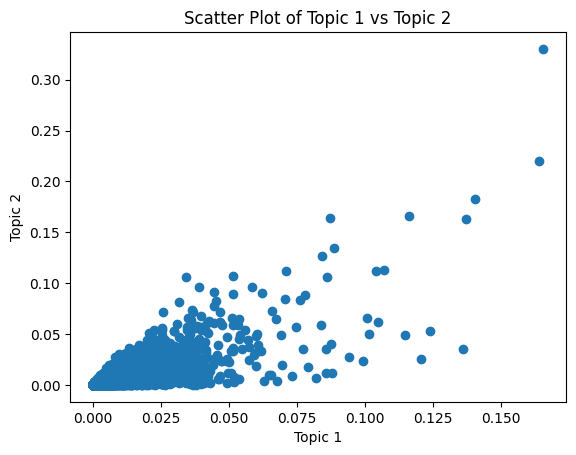

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.scatter(encoding_matrix["topic_1"], encoding_matrix["topic_2"])

ax.set_xlabel('Topic 1')
ax.set_ylabel('Topic 2')
ax.set_title('Scatter Plot of Topic 1 vs Topic 2')

plt.show()

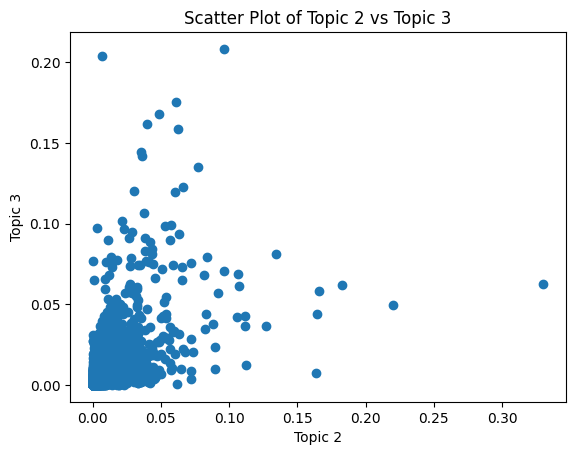

In [17]:
fig, ax = plt.subplots()

ax.scatter(encoding_matrix["topic_2"], encoding_matrix["topic_3"])

ax.set_xlabel('Topic 2')
ax.set_ylabel('Topic 3')
ax.set_title('Scatter Plot of Topic 2 vs Topic 3')

plt.show()

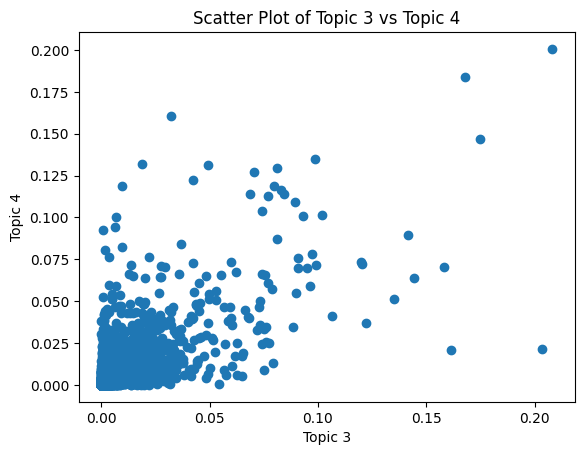

In [18]:
fig, ax = plt.subplots()

ax.scatter(encoding_matrix["topic_3"], encoding_matrix["topic_4"])

ax.set_xlabel('Topic 3')
ax.set_ylabel('Topic 4')
ax.set_title('Scatter Plot of Topic 3 vs Topic 4')

plt.show()

In [19]:
print(type(encoding_matrix["topic_2"]))

<class 'pandas.core.series.Series'>


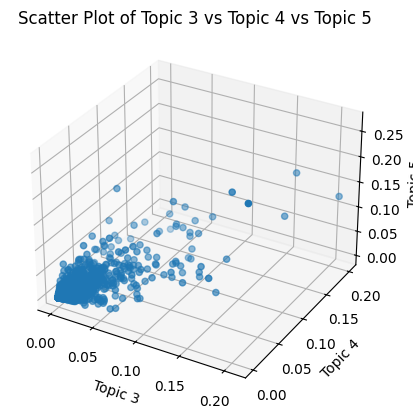

In [20]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(encoding_matrix["topic_3"].values, encoding_matrix["topic_4"].values, encoding_matrix["topic_5"].values)

ax.set_xlabel('Topic 3')
ax.set_ylabel('Topic 4')
ax.set_zlabel('Topic 5')
ax.set_title('Scatter Plot of Topic 3 vs Topic 4 vs Topic 5')

plt.show()

### Agrupamento com k-means

Inspirados pelos gráficos anteriores, podemos realizar um agrupamento dos dados, como já aprendemos na Disciplina de Aprendizado de máquina, podemos utilizar o k-means. Façamos isso então:

In [21]:
svd = TruncatedSVD(n_components=10)
kmeans = KMeans(n_clusters=10)
pipeline = make_pipeline(svd, kmeans)
pipeline.fit(csr_mat)
labels = pipeline.predict(csr_mat)

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [22]:
df = pd.DataFrame({'labels': labels, 'docs': titles, 'abstract': abstracts})
df.sort_values('labels')

,labels,docs,abstract
7109,0,Intrinsic thermal stability of inverted perovs...,thermal stability materials issue impairing lo...
1870,0,Surface Modification of NiOx Layer with Versat...,"recent years , nickel oxide ( niox ) widely ex..."
1871,0,Antimony doped CsPbI2Br for high-stability all...,"- inorganic perovskites , adopting cesium ( cs..."
1873,0,Slot-die coating fabrication of perovskite sol...,significant developments advantages solar cell...
6903,0,Design and Synthesis of Fluorinated Quantum Do...,dimensionality engineering involving low - dim...
...,...,...,...
2503,9,Fabrication of Ce-doped Hollow NiCo2O4 Nanopri...,reasonable design controlled synthesis efficie...
12362,9,Hydrogarnet-Derived Porous Polyhedral Particle...,introduction open mesoporosity microparticlesw...
4872,9,Layer-structured Li1-xNaxNi0.8Co0.15Al0.05O2-δ...,ceria electrolyte - based solid ceramic fuel c...
7712,9,A Novel High-Entropy Perovskite Electrolyte wi...,reversible protonic ceramic electrochemical ce...


Salvanto planilha com a classificação por tópicos.

In [23]:
df.to_excel('topics.xlsx')

# Playground